# Muestra del dataset Paraná
4 imágenes aleatorias por especie con su máscara (rosa claro) superpuesta.

In [3]:
from pathlib import Path
import random
import numpy as np
import cv2
import matplotlib.pyplot as plt

DS = Path("dataset")
N = 4
SEED = None          # poné un int para reproducir la selección
MASK_COLOR = (255, 215, 0)   # rosa clarito (RGB)
ALPHA = 0.55

rng = random.Random(SEED)
by_species = {}
for img in (DS / "images").glob("*/*"):
    if img.suffix.lower() in {".jpg", ".jpeg", ".png"}:
        by_species.setdefault(img.name.split("__")[0], []).append(img)
{k: len(v) for k, v in sorted(by_species.items())}

{'boga': 127,
 'dorado': 188,
 'palometa': 357,
 'sabalo': 269,
 'surubi_pintado': 104,
 'tararira': 271}

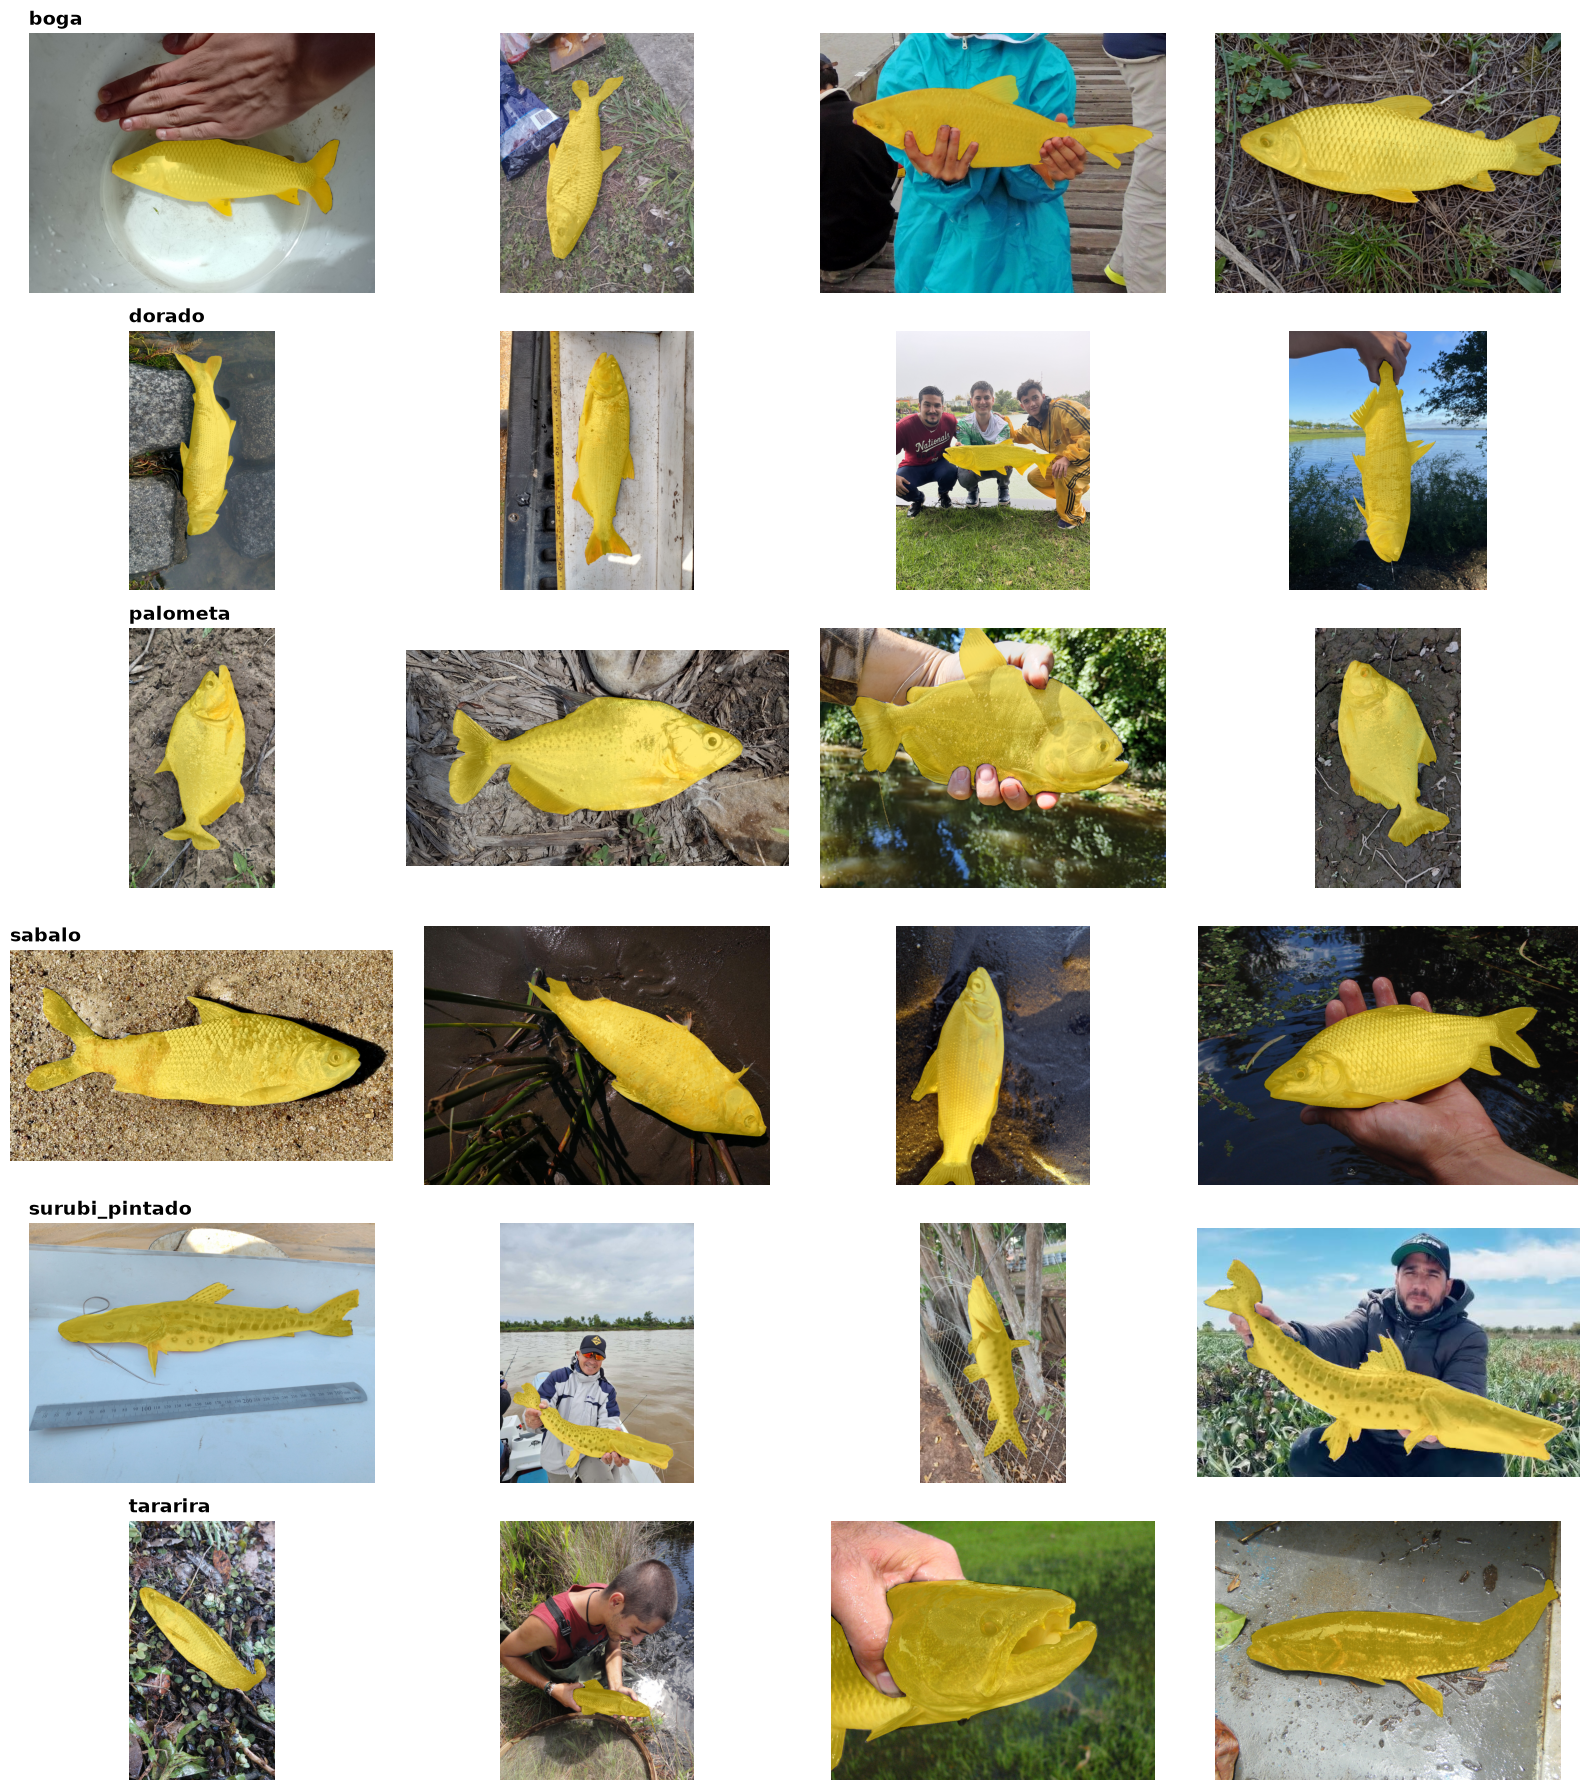

In [4]:
def load_overlay(img_path):
    im = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    h, w = im.shape[:2]
    lbl = DS / "labels" / img_path.parent.name / (img_path.stem + ".txt")
    mask = np.zeros((h, w), np.uint8)
    if lbl.exists():
        for line in lbl.read_text().splitlines():
            p = line.split()
            if len(p) < 7:
                continue
            pts = (np.array(p[1:], float).reshape(-1, 2) * [w, h]).astype(np.int32)
            cv2.fillPoly(mask, [pts], 1)
    out = im.copy()
    m = mask.astype(bool)
    out[m] = (im[m] * (1 - ALPHA) + np.array(MASK_COLOR) * ALPHA).astype(np.uint8)
    return out

species = sorted(by_species)
fig, axes = plt.subplots(len(species), N, figsize=(4 * N, 3 * len(species)))
for r, sp in enumerate(species):
    picks = rng.sample(by_species[sp], min(N, len(by_species[sp])))
    for c_ in range(N):
        ax = axes[r, c_]
        ax.axis("off")
        if c_ < len(picks):
            ax.imshow(load_overlay(picks[c_]))
        if c_ == 0:
            ax.set_title(sp, loc="left", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()